# Lab 6: Máy vectơ hỗ trợ (SVM)

## 2. Đường có lề rộng nhất (g1_le_rong_nhat.py)

In [1]:
# -*- coding: utf-8 -*-
"""Bước 1: tìm đường có lề rộng nhất và các vectơ hỗ trợ."""

import numpy as np
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

# 24 điểm, hai cụm tách hẳn nhau
X, y = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]],
                  cluster_std=0.9, random_state=0)
y = 1 - y            # lớp 1 là cụm dưới bên trái, giống hình trên slide

# C rất lớn nghĩa là không cho điểm nào nằm trong lề
svm = SVC(kernel="linear", C=1000)
svm.fit(X, y)

w = svm.coef_[0]
b = svm.intercept_[0]
print(f"w1 = {w[0]:.3f}, w2 = {w[1]:.3f}, b = {b:.3f}")
do_dai_w = np.sqrt(w[0] ** 2 + w[1] ** 2)
print(f"Do rong cua le = 2 / {do_dai_w:.4f} = {2 / do_dai_w:.4f}")
print()

# Các vectơ hỗ trợ nằm đúng trên hai mép lề, nơi f(x) bằng 1 hoặc -1
print("So vecto ho tro:", len(svm.support_))
for i in svm.support_:
    f = svm.decision_function(X[i:i + 1])[0]
    print(f"  diem {i:2d}: x1 = {X[i, 0]:.2f}, x2 = {X[i, 1]:.2f},"
          f" lop {y[i]}, f(x) = {f:+.3f}")
print()

# Những điểm khác nằm ngoài lề, nên |f(x)| lớn hơn 1
f_tat_ca = svm.decision_function(X)
ngoai = np.setdiff1d(np.arange(len(X)), svm.support_)
nho_nhat = np.abs(f_tat_ca[ngoai]).min()
print(f"|f(x)| nho nhat cua cac diem khac: {nho_nhat:.3f}")
print()

# Học lại chỉ với các vectơ hỗ trợ
chi_sv = SVC(kernel="linear", C=1000)
chi_sv.fit(X[svm.support_], y[svm.support_])
w2 = chi_sv.coef_[0]
print("Hoc lai chi voi vecto ho tro:")
b2 = chi_sv.intercept_[0]
print(f"  w1 = {w2[0]:.3f}, w2 = {w2[1]:.3f}, b = {b2:.3f}")
print()

# Dự đoán cho hai điểm mới
moi = np.array([[3.0, 3.0], [5.0, 4.5]])
for diem, f, lop in zip(moi, svm.decision_function(moi),
                        svm.predict(moi)):
    print(f"Diem ({diem[0]}, {diem[1]}): f(x) = {f:+.3f}, doan lop {lop}")

w1 = -0.831, w2 = -0.355, b = 4.820
Do rong cua le = 2 / 0.9039 = 2.2126

So vecto ho tro: 3
  diem 18: x1 = 5.20, x2 = 4.22, lop 0, f(x) = -1.000
  diem 10: x1 = 2.88, x2 = 4.02, lop 1, f(x) = +1.000
  diem 13: x1 = 3.59, x2 = 2.36, lop 1, f(x) = +1.000

|f(x)| nho nhat cua cac diem khac: 1.059

Hoc lai chi voi vecto ho tro:
  w1 = -0.831, w2 = -0.355, b = 4.821

Diem (3.0, 3.0): f(x) = +1.262, doan lop 1
Diem (5.0, 4.5): f(x) = -0.933, doan lop 0


## 3. Lề mềm và tham số C (g2_tham_so_c.py)

In [2]:
"""Bước 2: lề mềm, tham số C, và vì sao SVM phải chuẩn hoá."""

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

df = pd.read_csv("sinh_vien.csv")
X = df[["gio_on", "diem_giua_ky"]]
y = df["qua_mon"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("Tap hoc co", len(X_tr), "ban")
print("    C    so vecto HT   do rong le   tap hoc   tap kiem tra")
for C in [0.01, 0.1, 1, 10, 100]:
    mh = make_pipeline(StandardScaler(),
                       SVC(kernel="linear", C=C))
    mh.fit(X_tr, y_tr)
    svm = mh[-1]                     # bước cuối của pipeline là SVM
    le = 2 / np.linalg.norm(svm.coef_[0])
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {C:6}   {len(svm.support_):6d}       {le:6.2f}"
          f"      {a_hoc:.4f}    {a_kt:.4f}")
print()

# Bộ sinh viên mở rộng có thêm cột chi tiêu, tính bằng nghìn đồng
df3 = pd.read_csv("sinh_vien_mo_rong.csv")
X3 = df3[["gio_on", "diem_giua_ky", "chi_tieu"]]
y3 = df3["qua_mon"]
X3_tr, X3_te, y3_tr, y3_te = train_test_split(
    X3, y3, test_size=0.25, random_state=17, stratify=y3
)
tho = SVC().fit(X3_tr, y3_tr)
chuan = make_pipeline(StandardScaler(), SVC()).fit(X3_tr, y3_tr)
print("Ba cot, kernel RBF mac dinh")
print(f"  Doan bua ca lop qua : {y3_te.mean():.4f}")
print(f"  Khong chuan hoa     : "
      f"{accuracy_score(y3_te, tho.predict(X3_te)):.4f}")
print(f"  Co chuan hoa        : "
      f"{accuracy_score(y3_te, chuan.predict(X3_te)):.4f}")

Tap hoc co 90 ban
    C    so vecto HT   do rong le   tap hoc   tap kiem tra
    0.01       74         3.84      0.8556    0.8667
     0.1       44         1.70      0.8889    0.9000
       1       31         1.29      0.8778    0.9000
      10       28         1.06      0.9000    0.9000
     100       27         1.05      0.9000    0.9000

Ba cot, kernel RBF mac dinh
  Doan bua ca lop qua : 0.6000
  Khong chuan hoa     : 0.6000
  Co chuan hoa        : 0.9000


## 4. Kernel và biên cong (g3_kernel.py)

In [3]:
"""Bước 3: nâng chiều bằng tay, rồi để kernel làm việc đó."""

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Phần 1: dữ liệu một chiều, lớp 1 nằm giữa, lớp 0 ở hai đầu
x = np.array([-4.0, -3.4, -2.8, -2.2, -1.2, -0.7, -0.2,
              0.3, 0.8, 1.3, 2.3, 2.9, 3.5, 4.0])
y = (np.abs(x) < 1.8).astype(int)

# Thử mọi ngưỡng: đoán lớp 1 khi x nhỏ hơn hoặc bằng ngưỡng
tot = max(((x <= t).astype(int) == y).mean() for t in x)
print(f"Mot nguong tren truc x, tot nhat dung {tot:.4f}")

# Thêm cột x bình phương rồi dùng SVM tuyến tính
X_moi = np.c_[x, x ** 2]
svm = SVC(kernel="linear", C=1000).fit(X_moi, y)
print(f"Them cot x^2, SVM tuyen tinh dung {svm.score(X_moi, y):.4f}")
print()

# Phần 2: hai vầng trăng, để kernel tự nâng chiều
df = pd.read_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mo_hinh = {
    "SVM kernel tuyen tinh": SVC(kernel="linear"),
    "SVM kernel da thuc bac 3": SVC(kernel="poly", degree=3),
    "SVM kernel RBF": SVC(kernel="rbf"),
    "Hoi quy logistic": LogisticRegression(),
    "KNN, k = 13": KNeighborsClassifier(n_neighbors=13),
}
print("Hai vang trang, accuracy tren tap kiem tra")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {ten:26s} {acc:.4f}")
print()

rbf = mo_hinh["SVM kernel RBF"]
print("So vecto ho tro cua kernel RBF:", len(rbf.support_),
      "tren", len(X_tr), "diem hoc")

Mot nguong tren truc x, tot nhat dung 0.7143
Them cot x^2, SVM tuyen tinh dung 1.0000

Hai vang trang, accuracy tren tap kiem tra
  SVM kernel tuyen tinh      0.8667
  SVM kernel da thuc bac 3   0.8667
  SVM kernel RBF             0.9200
  Hoi quy logistic           0.8533
  KNN, k = 13                0.9200

So vecto ho tro cua kernel RBF: 89 tren 225 diem hoc


## 5. Chọn C và gamma (g4_chon_tham_so.py)

In [4]:
"""Bước 4: ảnh hưởng của gamma, rồi dò lưới C và gamma."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.svm import SVC

df = pd.read_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("gamma   tap hoc   tap kiem tra   so vecto HT")
for g in [0.1, 1, 10, 100]:
    mh = SVC(kernel="rbf", gamma=g).fit(X_tr, y_tr)
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {g:5}  {a_hoc:.4f}    {a_kt:.4f}         "
          f"{len(mh.support_)}")
print()

# Dò lưới: thử mọi cặp bằng kiểm định chéo 5 phần, chỉ trên tập học
luoi = {"C": [0.1, 1, 10, 100], "gamma": [0.01, 0.1, 1, 10]}
tim = GridSearchCV(SVC(kernel="rbf"), luoi, cv=5)
tim.fit(X_tr, y_tr)

bang = pd.DataFrame(tim.cv_results_["params"])
bang["diem"] = tim.cv_results_["mean_test_score"]
print("Diem kiem dinh cheo, hang la C, cot la gamma")
print(bang.pivot(index="C", columns="gamma",
                 values="diem").round(4).to_string())
print()

print("Cap tot nhat:", tim.best_params_)
print(f"Diem kiem dinh cheo: {tim.best_score_:.4f}")
# GridSearchCV đã tự học lại với cặp tốt nhất trên toàn tập học
print(f"Accuracy tren tap kiem tra: {tim.score(X_te, y_te):.4f}")

gamma   tap hoc   tap kiem tra   so vecto HT
    0.1  0.8356    0.8533         113
      1  0.8711    0.9200         88
     10  0.8978    0.9067         128
    100  0.9422    0.8133         217



Diem kiem dinh cheo, hang la C, cot la gamma
gamma   0.01    0.10    1.00    10.00
C                                    
0.1    0.6578  0.8044  0.8444  0.8578
1.0    0.8044  0.8178  0.8667  0.8667
10.0   0.8178  0.8400  0.8711  0.8311
100.0  0.8178  0.8533  0.8711  0.7467

Cap tot nhat: {'C': 10, 'gamma': 1}
Diem kiem dinh cheo: 0.8711
Accuracy tren tap kiem tra: 0.9200


## 6. Nhận dạng chữ số viết tay (g5_chu_so.py)

In [5]:
"""Bước 5: nhận dạng chữ số viết tay bằng SVM."""

import numpy as np
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
print("Kich thuoc X:", X.shape)
print("Do sang nho nhat va lon nhat:", X.min(), X.max())
print("So anh moi chu so:", np.bincount(y))
print()

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

svm = SVC(kernel="rbf").fit(X_tr, y_tr)
du_doan = svm.predict(X_te)
print(f"SVM kernel RBF: accuracy {accuracy_score(y_te, du_doan):.4f}")
print("So vecto ho tro:", len(svm.support_), "tren", len(X_tr), "anh")
sai = np.flatnonzero(du_doan != y_te)
print("So anh doan sai:", len(sai), "tren", len(y_te))
for i in sai:
    print(f"  anh {i:3d}: that la {y_te[i]}, doan la {du_doan[i]}")
print()

# So với các mô hình đã học
mo_hinh = {
    "SVM co chuan hoa": make_pipeline(StandardScaler(), SVC()),
    "KNN, k = 5": KNeighborsClassifier(),
    "Logistic co chuan hoa": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000)),
}
print("Cac mo hinh khac, accuracy tren tap kiem tra")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {ten:22s} {acc:.4f}")

Kich thuoc X: (1797, 64)
Do sang nho nhat va lon nhat: 0.0 16.0
So anh moi chu so: [178 182 177 183 181 182 181 179 174 180]

SVM kernel RBF: accuracy 0.9911
So vecto ho tro: 626 tren 1347 anh
So anh doan sai: 4 tren 450
  anh   6: that la 9, doan la 3
  anh  18: that la 8, doan la 1
  anh 161: that la 4, doan la 8
  anh 428: that la 7, doan la 9

Cac mo hinh khac, accuracy tren tap kiem tra
  SVM co chuan hoa       0.9778


  KNN, k = 5             0.9867
  Logistic co chuan hoa  0.9711


## 7. Bài tập
### Bài tập 1: Tính tay khoảng cách tới ranh giới

In [6]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

X, y = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]],
                  cluster_std=0.9, random_state=0)
y = 1 - y
svm = SVC(kernel="linear", C=1000).fit(X, y)
w1, w2 = svm.coef_[0]
b = svm.intercept_[0]
do_dai_w = np.sqrt(w1 ** 2 + w2 ** 2)
do_rong_le = 2 / do_dai_w
print(f"w1 = {w1:.4f}, w2 = {w2:.4f}, b = {b:.4f}, |w| = {do_dai_w:.4f}")
print(f"Do rong le = {do_rong_le:.4f}, nua le = {do_rong_le / 2:.4f}")
print()

print("Hai diem moi (tu nhan va cong, khong dung decision_function):")
for x1, x2 in [(3.0, 3.0), (5.0, 4.5)]:
    f = w1 * x1 + w2 * x2 + b
    kc = abs(f) / do_dai_w
    print(f"  ({x1}, {x2}): f = {w1:.4f}*{x1} + ({w2:.4f})*{x2} + {b:.4f}"
          f" = {f:+.4f}, khoang cach = {kc:.4f}")
print()

print("Ba vecto ho tro:")
for i in svm.support_:
    f = w1 * X[i, 0] + w2 * X[i, 1] + b
    print(f"  diem {i:2d} ({X[i, 0]:.2f}, {X[i, 1]:.2f}): f = {f:+.4f},"
          f" khoang cach = {abs(f) / do_dai_w:.4f}")

w1 = -0.8314, w2 = -0.3549, b = 4.8204, |w| = 0.9039
Do rong le = 2.2126, nua le = 1.1063

Hai diem moi (tu nhan va cong, khong dung decision_function):
  (3.0, 3.0): f = -0.8314*3.0 + (-0.3549)*3.0 + 4.8204 = +1.2617, khoang cach = 1.3958
  (5.0, 4.5): f = -0.8314*5.0 + (-0.3549)*4.5 + 4.8204 = -0.9333, khoang cach = 1.0325

Ba vecto ho tro:
  diem 18 (5.20, 4.22): f = -1.0001, khoang cach = 1.1064
  diem 10 (2.88, 4.02): f = +0.9999, khoang cach = 1.1062
  diem 13 (3.59, 2.36): f = +1.0002, khoang cach = 1.1065


### Bài tập 2: Thêm một điểm

In [7]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

X, y = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]],
                  cluster_std=0.9, random_state=0)
y = 1 - y


def hoc_va_in(ten, X, y):
    svm = SVC(kernel="linear", C=1000).fit(X, y)
    w, b = svm.coef_[0], svm.intercept_[0]
    print(f"{ten:28s} w1 = {w[0]:.3f}, w2 = {w[1]:.3f}, b = {b:.3f},"
          f" so SV = {len(svm.support_)}, le = {2 / np.linalg.norm(w):.4f}")
    return svm


goc = hoc_va_in("24 diem goc", X, y)
them_xa = hoc_va_in("Them (-1, -1) lop 1",
                    np.vstack([X, [-1, -1]]), np.append(y, 1))
f_xa = goc.decision_function([[-1, -1]])[0]
print(f"  f(-1, -1) theo mo hinh goc = {f_xa:+.3f} (>1, nam ngoai le)")
them_gan = hoc_va_in("Them (4.5, 4) lop 1",
                     np.vstack([X, [4.5, 4]]), np.append(y, 1))
f_gan = goc.decision_function([[4.5, 4]])[0]
print(f"  f(4.5, 4) theo mo hinh goc = {f_gan:+.3f} (<1, nam trong le)")

24 diem goc                  w1 = -0.831, w2 = -0.355, b = 4.820, so SV = 3, le = 2.2126
Them (-1, -1) lop 1          w1 = -0.831, w2 = -0.355, b = 4.820, so SV = 3, le = 2.2126
  f(-1, -1) theo mo hinh goc = +6.007 (>1, nam ngoai le)
Them (4.5, 4) lop 1          w1 = -2.603, w2 = -0.807, b = 15.941, so SV = 2, le = 0.7339
  f(4.5, 4) theo mo hinh goc = -0.340 (<1, nam trong le)


### Bài tập 3: Kernel đa thức

In [8]:
import pandas as pd
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

df = pd.read_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("bac   C tot nhat   kiem dinh cheo   tap kiem tra")
for d in [2, 3, 4]:
    mh = make_pipeline(StandardScaler(), SVC(kernel="poly", degree=d))
    tim = GridSearchCV(mh, {"svc__C": [0.1, 1, 10, 100]}, cv=5)
    tim.fit(X_tr, y_tr)
    print(f"  {d}     {tim.best_params_['svc__C']:6}       "
          f"{tim.best_score_:.4f}         {tim.score(X_te, y_te):.4f}")
print("Kernel RBF o muc 5: kiem dinh cheo 0.8711, tap kiem tra 0.9200")

bac   C tot nhat   kiem dinh cheo   tap kiem tra
  2          1       0.5422         0.5067


  3          1       0.8178         0.8267


  4        100       0.5156         0.4800
Kernel RBF o muc 5: kiem dinh cheo 0.8711, tap kiem tra 0.9200


### Bài tập 4: Dò lưới mịn

In [9]:
import pandas as pd
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.svm import SVC

df = pd.read_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

luoi_min = {"C": [3, 10, 30], "gamma": [0.3, 1, 3]}
tim = GridSearchCV(SVC(kernel="rbf"), luoi_min, cv=5).fit(X_tr, y_tr)
bang = pd.DataFrame(tim.cv_results_["params"])
bang["diem"] = tim.cv_results_["mean_test_score"]
print(bang.pivot(index="C", columns="gamma", values="diem").round(4).to_string())
print()
print("Cap tot nhat:", tim.best_params_)
print(f"Diem kiem dinh cheo: {tim.best_score_:.4f} (luoi thua: 0.8711)")
print(f"Accuracy tap kiem tra: {tim.score(X_te, y_te):.4f} (luoi thua: 0.9200)")

gamma     0.3     1.0     3.0
C                            
3      0.8533  0.8711  0.8667
10     0.8489  0.8711  0.8667
30     0.8622  0.8756  0.8533

Cap tot nhat: {'C': 30, 'gamma': 1}
Diem kiem dinh cheo: 0.8756 (luoi thua: 0.8711)
Accuracy tap kiem tra: 0.9200 (luoi thua: 0.9200)


### Bài tập 5: Chữ số viết tay, những lỗi nào hay gặp

Hang la chu so that, cot la chu so doan:
    0   1   2   3   4   5   6   7   8   9
0  45   0   0   0   0   0   0   0   0   0
1   0  46   0   0   0   0   0   0   0   0
2   0   0  44   0   0   0   0   0   0   0
3   0   0   0  46   0   0   0   0   0   0
4   0   0   0   0  44   0   0   0   1   0
5   0   0   0   0   0  46   0   0   0   0
6   0   0   0   0   0   0  45   0   0   0
7   0   0   0   0   0   0   0  44   0   1
8   0   1   0   0   0   0   0   0  42   0
9   0   0   0   1   0   0   0   0   0  44

Cac cap bi nham (that -> doan):
  4 -> 8: 1 anh
  7 -> 9: 1 anh
  8 -> 1: 1 anh
  9 -> 3: 1 anh


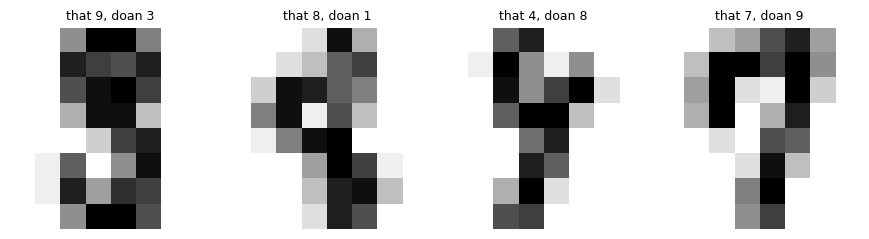

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
du_doan = SVC(kernel="rbf").fit(X_tr, y_tr).predict(X_te)

bang = confusion_matrix(y_te, du_doan)
print("Hang la chu so that, cot la chu so doan:")
print(pd.DataFrame(bang, index=range(10), columns=range(10)).to_string())
print()
print("Cac cap bi nham (that -> doan):")
for t in range(10):
    for d in range(10):
        if t != d and bang[t, d] > 0:
            print(f"  {t} -> {d}: {bang[t, d]} anh")

sai = np.flatnonzero(du_doan != y_te)
fig, axes = plt.subplots(1, len(sai), figsize=(2.2 * len(sai), 2.6))
for ax, i in zip(np.atleast_1d(axes), sai):
    ax.imshow(X_te[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"that {y_te[i]}, doan {du_doan[i]}", fontsize=9)
    ax.axis("off")
    plt.imsave(f"anh_sai_{i}.png", X_te[i].reshape(8, 8), cmap="gray_r")
plt.tight_layout()
plt.show()

### Bài tập 6: SVM trên dữ liệu lớn

In [11]:
import time

from sklearn.datasets import make_classification
from sklearn.svm import SVC, LinearSVC

print("      n     SVC (s)   LinearSVC (s)")
for n in [2000, 5000, 10000, 20000]:
    X, y = make_classification(n_samples=n, n_features=20, random_state=0)
    bd = time.perf_counter()
    SVC().fit(X, y)
    t_svc = time.perf_counter() - bd
    bd = time.perf_counter()
    LinearSVC().fit(X, y)
    t_lin = time.perf_counter() - bd
    print(f"  {n:6d}   {t_svc:8.3f}   {t_lin:10.4f}")

      n     SVC (s)   LinearSVC (s)
    2000      0.026       0.0032


    5000      0.192       0.0041


   10000      1.914       0.0068


   20000      5.106       0.0202


## Summary

**Phần thực hành** (khớp các con số của tài liệu)
- 24 điểm tách được: w1 = -0.831, w2 = -0.355, b = 4.820, lề rộng 2.2126, có 3 vectơ hỗ trợ. Học lại chỉ với 3 vectơ hỗ trợ cho lại đúng đường ranh giới.
- Tham số C (0.01 → 100): số vectơ hỗ trợ giảm 74 → 27, lề giảm 3.84 → 1.05, tập kiểm tra 0.8667 → 0.9000. Ba cột không chuẩn hoá 0.6000 (bằng đoán bừa), có chuẩn hoá 0.9000.
- Hai vầng trăng: kernel tuyến tính 0.8667, đa thức bậc 3 0.8667, RBF 0.9200 (89 vectơ hỗ trợ trên 225 điểm). Gamma 100 thì học vẹt: tập học 0.9422, tập kiểm tra 0.8133.
- Dò lưới: tốt nhất C = 10, gamma = 1, kiểm định chéo 0.8711, tập kiểm tra 0.9200.
- Chữ số: SVM RBF 0.9911 (sai 4/450), KNN 0.9867, logistic 0.9711, SVM có chuẩn hoá chỉ 0.9778.

**Bài tập**
1. f(3, 3) = +1.2617, khoảng cách 1.3958. f(5, 4.5) = -0.9333, khoảng cách 1.0325, nhỏ hơn nửa lề (1.1063) nên nằm trong lề. Ba vectơ hỗ trợ đều cách ranh giới ≈ 1.1063. Vectơ hỗ trợ có |f(x)| = 1 nên khoảng cách = 1/‖w‖ = (2/‖w‖)/2, đúng bằng nửa độ rộng lề.
2. Thêm (-1, -1) lớp 1: w, b **không đổi**, vì điểm này có f = +6.0 > 1, nằm xa ngoài lề và không thành vectơ hỗ trợ. Thêm (4.5, 4) lớp 1: đường ranh giới **đổi hẳn** (w1 = -2.603, w2 = -0.807, b = 15.941, lề co từ 2.21 xuống 0.73). Điểm này có f = -0.34, nằm trong lề và ở sai phía, nên nó trở thành vectơ hỗ trợ mới và kéo ranh giới đi. Chỉ vectơ hỗ trợ mới quyết định ranh giới.
3. Bậc 2: kiểm định chéo 0.5422, tập kiểm tra 0.5067. Bậc 3 (C = 1): 0.8178 / 0.8267, **tốt nhất**. Bậc 4 (C = 100): 0.5156 / 0.4800. Bậc chẵn cho ranh giới đối xứng qua gốc toạ độ nên không hợp hai vầng trăng. Không bậc nào vượt RBF (0.8711 / 0.9200).
4. Lưới mịn: tốt nhất C = 30, gamma = 1, kiểm định chéo 0.8756, chỉ hơn 0.8711 một chút (khoảng 1 điểm trên 225). Tập kiểm tra giữ nguyên 0.9200. Dò thật mịn tốn nhiều lần học mà lợi ích nằm trong mức dao động của kiểm định chéo, nên lưới thưa đã đủ.
5. Có 4 cặp nhầm, mỗi cặp 1 ảnh: 4 → 8, 7 → 9, 8 → 1, 9 → 3. Ở độ phân giải 8 × 8 các ảnh này viết lệch hoặc thiếu nét: chữ 9 có vòng dưới hở nên giống 3, chữ 7 có nét ngang cong giống đầu chữ 9, chữ 8 bị bóp hẹp như số 1. Các ảnh sai được lưu thành `anh_sai_*.png`.
6. SVC (kernel RBF): khi n gấp đôi, thời gian học tăng khoảng 3 đến 10 lần (5 000 → 10 000: ~0.19 s → ~1.9 s; 10 000 → 20 000: ~1.9 s → ~5.1 s), tức nhanh hơn tuyến tính, cỡ bậc hai trở lên. LinearSVC tăng gần tuyến tính, khoảng 1.5 đến 3 lần, và nhanh hơn hàng trăm lần (0.02 s ở n = 20 000). Thời gian cụ thể khác nhau giữa các lần chạy, chỉ nên so tương đối.